In [2]:
import pandas as pd

df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")

print("Dataset loaded successfully!")









Dataset loaded successfully!


In [3]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [4]:
df.shape

(1470, 35)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [6]:
df.duplicated().sum()


np.int64(0)

In [7]:
df['Attrition'].value_counts()

Attrition
No     1233
Yes     237
Name: count, dtype: int64

In [8]:
df['Attrition'].value_counts(normalize=True) * 100

Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64

In [9]:
df.groupby('Department')['Attrition'].value_counts()

Department              Attrition
Human Resources         No            51
                        Yes           12
Research & Development  No           828
                        Yes          133
Sales                   No           354
                        Yes           92
Name: count, dtype: int64

In [10]:
department_attrition = (
    df.groupby('Department')['Attrition']
    .apply(lambda x: (x == 'Yes').mean() * 100)
)

department_attrition

Department
Human Resources           19.047619
Research & Development    13.839750
Sales                     20.627803
Name: Attrition, dtype: float64

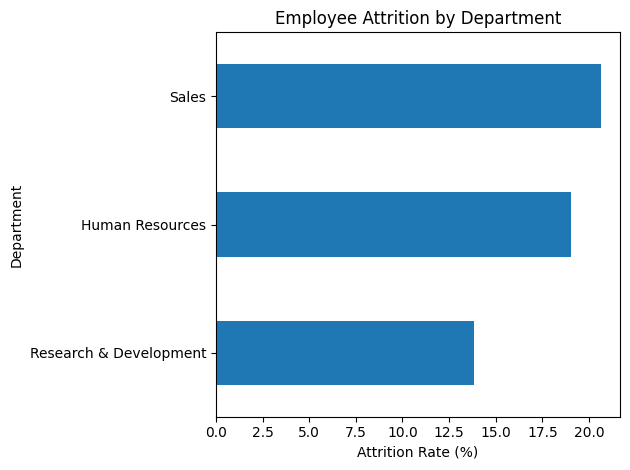

In [11]:
import matplotlib.pyplot as plt

department_attrition.sort_values().plot(
    kind='barh',
    title='Employee Attrition by Department',
    xlabel='Attrition Rate (%)',
    ylabel='Department'
)

plt.tight_layout()
plt.show()


In [12]:
df.groupby('OverTime')['Attrition'].value_counts()

OverTime  Attrition
No        No           944
          Yes          110
Yes       No           289
          Yes          127
Name: count, dtype: int64

In [13]:
overtime_attrition = (
    df.groupby('OverTime')['Attrition']
    .apply(lambda x: (x == 'Yes').mean() * 100)
)

overtime_attrition

OverTime
No     10.436433
Yes    30.528846
Name: Attrition, dtype: float64

In [14]:
df.groupby('Attrition')['JobSatisfaction'].mean()

Attrition
No     2.778589
Yes    2.468354
Name: JobSatisfaction, dtype: float64

In [15]:
df.groupby('Attrition')['MonthlyIncome'].mean()

Attrition
No     6832.739659
Yes    4787.092827
Name: MonthlyIncome, dtype: float64

In [16]:
hr_summary = df.groupby('Attrition').agg(
    Employee_Count=('EmployeeNumber', 'count'),
    Average_Satisfaction=('JobSatisfaction', 'mean'),
    Average_Monthly_Income=('MonthlyIncome', 'mean'),
    Average_Years_At_Company=('YearsAtCompany', 'mean')
)

hr_summary

,Employee_Count,Average_Satisfaction,Average_Monthly_Income,Average_Years_At_Company
Attrition,,,,
No,1233,2.778589,6832.739659,7.369019
Yes,237,2.468354,4787.092827,5.130802


In [17]:
df.groupby('Attrition')['YearsAtCompany'].describe()

,count,mean,std,min,25%,50%,75%,max
Attrition,,,,,,,,
No,1233.0,7.369019,6.096298,0.0,3.0,6.0,10.0,37.0
Yes,237.0,5.130802,5.949984,0.0,1.0,3.0,7.0,40.0


In [18]:
df['TenureGroup'] = pd.cut(
    df['YearsAtCompany'],
    bins=[-1, 1, 3, 5, 10, 50],
    labels=['0-1 years', '2-3 years',
            '4-5 years', '6-10 years', '10+ years']
)


In [22]:
tenure_attrition = (
    df.groupby('TenureGroup', observed=False)['Attrition']
    .apply(lambda x: (x == 'Yes').mean() * 100)
)

tenure_attrition

TenureGroup
0-1 years     34.883721
2-3 years     18.431373
4-5 years     13.071895
6-10 years    12.276786
10+ years      8.130081
Name: Attrition, dtype: float64

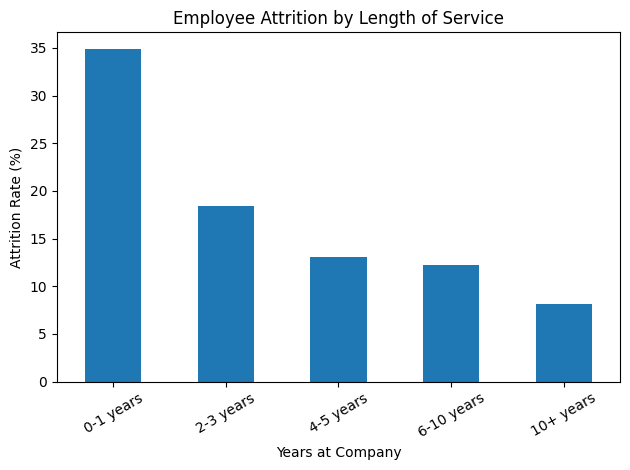

In [23]:
tenure_attrition.plot(
    kind='bar',
    title='Employee Attrition by Length of Service',
    xlabel='Years at Company',
    ylabel='Attrition Rate (%)',
    rot=30
)

plt.tight_layout()
plt.show()









In [24]:
import os

df.to_csv(
    'IBM_HR_Analytics_Clean.csv',
    index=False,
    encoding='ascii'
)

print("File created successfully!")
print(os.getcwd())

File created successfully!
/Users/khadijabegum


In [25]:
print(os.getcwd())

/Users/khadijabegum


In [26]:
import os

output_path = os.path.expanduser("~/Desktop/IBM_HR_Analytics_Clean.csv")

df.to_csv(output_path, index=False, encoding="ascii")

print("Saved to Desktop!")
print(output_path)

Saved to Desktop!
/Users/khadijabegum/Desktop/IBM_HR_Analytics_Clean.csv
